In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

In [2]:
P_in = 6e5
P_out = 5.45e5

In [3]:
# Fluid properties (from Table 3.1 and text)
gamma = 1.41  # Approximate gamma = cp / cv
R = 287  # J/kg·K (adjusted to standard air for simplicity; thesis uses ~306)
cp = 1050  # J/kg·K
cv = 744  # J/kg·K

# Pressures (Pa)
P_in = 6e5
P_out = 5.45e5
P0 = 5.725e5 # Initial average pressure

# Temperatures (K)
T_in = 300
T0 = T_in

# Resonator geometry
A_neck = 2.85e-4  # m²
L_neck = 0.15  # m
m_gas = 0.0015  # kg
V0_cv = 3e-5  # m³ (calculated from k_cv)
V0_pass = 3.93e-4  # m³ (calculated from k_passive)

# Damping from Q = 60
f = 135 # Hz
omega = 2 * np.pi * f
Q = 60
b_gas = 0.005#omega * m_gas / Q

# Reed parameters (for zeta = 0.6 example)
zeta = 0.6
dP = P_in - P_out
dP_max = dP / (2 * zeta)  # Symmetric inlet/outlet
dP_max_out = dP_max
m_max = 0.001  # kg/s (adjust this to match amplitude; thesis implies ~0.001 for m_avg ~0.00037)
m_max_factor = 1.78
m_max_out = 0.001 * m_max_factor
# Time span
t_span = (0, 10)  # s (adjust for more cycles)
t_eval = np.linspace(*t_span, 5000000)  # High resolution

# Initial conditions
x0 = 0.01 * L_neck  # Small disturbance
v0 = -5
M0_cv = P0 * V0_cv / (R * T0)
E0_cv = cv * M0_cv * T0
y0 = [x0, v0, M0_cv, E0_cv]

In [13]:
def reed_flow(dP, m_max, dP_max):
    """Mass flow rate through reed valve (positive for flow from high to low pressure)."""
    # return dP*1e-9
    u = dP / dP_max
    if dP > 0 and dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return - m_max * (1 - u) * np.sqrt(np.abs(u))
    else:
        return 0.0



In [14]:
def acoustic_expander_ode_asymmetric(t, y):
    x, v, M_cv, E_cv = y

    V_cv = V0_cv + x * A_neck
    T_cv = E_cv / (cv * M_cv) if M_cv > 0 else T0
    P_cv = M_cv * R * T_cv / V_cv

    V_pass = V0_pass - x * A_neck
    P_pass = P0 * (V0_pass / V_pass)**gamma if V_pass > 0 else P0

    dP_in = P_in - P_cv
    dP_out = P_cv - P_out

    m_in = reed_flow(dP_in,m_max,dP_max)
    m_out = reed_flow(dP_out,m_max_out,dP_max_out)

    dV_cv_dt = A_neck * v
    dM_dt = m_in - m_out
    dE_dt = -P_cv * dV_cv_dt + m_in * cp * T_in - m_out * cp * T_cv

    dx_dt = v
    dv_dt = (P_cv - P_pass) * A_neck / m_gas - (b_gas / m_gas) * v

    return [dx_dt, dv_dt, dM_dt, dE_dt]

def acoustic_expander_ode(t, y):
    x, v, M_cv, E_cv = y

    V_cv = V0_cv + x * A_neck
    T_cv = E_cv / (cv * M_cv) if M_cv > 0 else T0
    P_cv = M_cv * R * T_cv / V_cv

    V_pass = V0_pass - x * A_neck
    P_pass = P0 * (V0_pass / V_pass)**gamma if V_pass > 0 else P0

    dP_in = P_in - P_cv
    dP_out = P_cv - P_out

    m_in = reed_flow(dP_in,m_max,dP_max)
    m_out = reed_flow(dP_out,m_max,dP_max)

    dV_cv_dt = A_neck * v
    dM_dt = m_in - m_out
    dE_dt = -P_cv * dV_cv_dt + m_in * cp * T_in - m_out * cp * T_cv

    dx_dt = v
    dv_dt = (P_cv - P_pass) * A_neck / m_gas - (b_gas / m_gas) * v

    return [dx_dt, dv_dt, dM_dt, dE_dt]

In [15]:
sol = solve_ivp(acoustic_expander_ode, t_span, y0, t_eval=t_eval, method='RK45', rtol=1e-6, atol=1e-8)
#sol = solve_ivp(acoustic_expander_ode_asymmetric, t_span, y0, t_eval=t_eval, method='RK45', rtol=1e-6, atol=1e-8)

# Extract results
t = sol.t
x = sol.y[0]
v = sol.y[1]
M_cv = sol.y[2]
E_cv = sol.y[3]

V_cv = V0_cv + x * A_neck
T_cv = E_cv / (cv * M_cv)
P_cv = M_cv * R * T_cv / V_cv


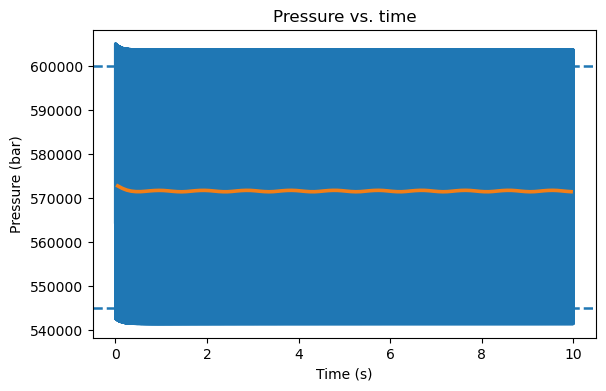

In [16]:
# ----------------------------
# Your parameters
# ----------------------------
n_average = 50000  # number of points we are averaging out

# ----------------------------
# Safe block-averaging (handles leftover points)
# ----------------------------
N = len(t)
M = (N // n_average) * n_average  # truncate to multiple
t_trim = t[:M]
P_trim = P_cv[:M]

t_avg = t_trim.reshape(-1, n_average).mean(axis=1)
P_avg = P_trim.reshape(-1, n_average).mean(axis=1)

# ----------------------------
# Plot
# ----------------------------
fig, ax = plt.subplots(figsize=(6.5, 4.0))  # journal-friendly aspect ratio

lw_main = 2.2
lw_ref  = 1.8

ax.plot(t, P_cv, linewidth=lw_main, label="Control volume pressure")
ax.axhline(P_in,  linewidth=lw_ref, linestyle="--", label="Inlet pressure")
ax.axhline(P_out, linewidth=lw_ref, linestyle="--", label="Outlet pressure")

# Averaged curve: make it visually distinct without changing colors explicitly
ax.plot(t_avg, P_avg, linewidth=2.6, alpha=0.95, label=f"Block average (N={n_average:,})")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Pressure (bar)")
ax.set_title("Pressure vs. time")


plt.show()

In [53]:
m_in = np.zeros_like(P_cv)
m_out = np.zeros_like(P_cv)
for i in range(len(P_cv)):
  dP_in = P_in - P_cv[i]
  dP_out = P_cv[i] - P_out
  m_in[i] = reed_flow(dP_in,m_max,dP_max)
  m_out[i] = -reed_flow(dP_out,m_max,dP_max)
m = m_in + m_out

np.savez_compressed(f"run_dP_max_out={m_max_factor:.2f}.npz", P_cv=P_cv)
# np.savez_compressed("run_void_bgas=0.002042.npz", t=t, v=v, P_cv=P_cv)

KeyboardInterrupt: 

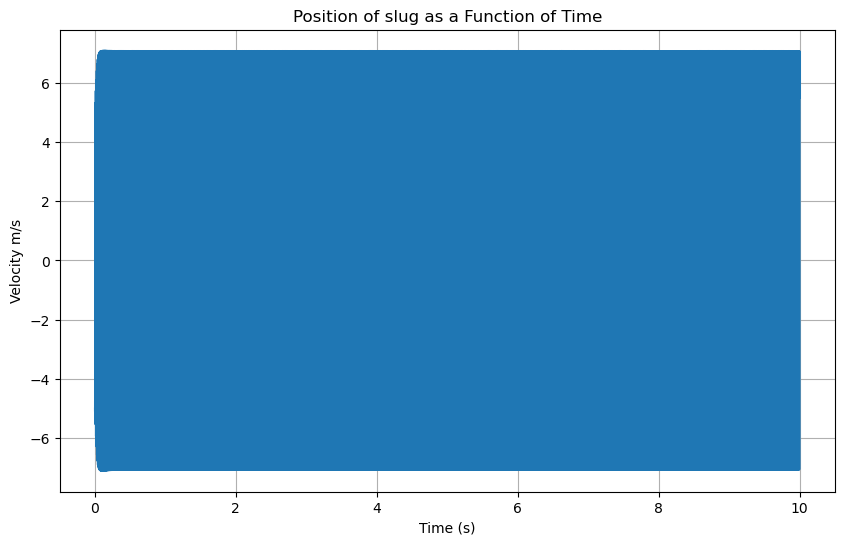

In [ ]:
n_average = 500000 # number of points we are averaging out

plt.figure(figsize=(10, 6))
plt.plot(t, v, label='Control Volume Pressure (bar)')
plt.xlabel('Time (s)')
plt.ylabel('Velocity m/s')
plt.title('Position of slug as a Function of Time')
#plt.legend()
plt.grid(True)
#plt.savefig(f"plots/Pressure_Oscillation_P_0={P0:.1f}__v0={v0:.2f}__f={f}_x0={x0}.pdf")
plt.show()


/Users/a1/miniforge3/envs/acoustic/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


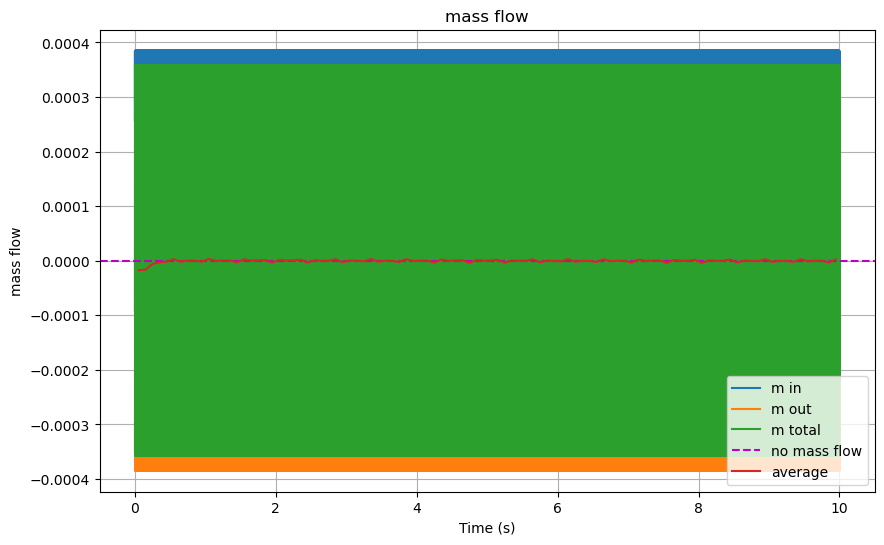

In [ ]:
n_average = 50000 # number of points we are averaging out



plt.figure(figsize=(10, 6))
plt.plot(t,m_in, label='m in')
plt.plot(t,m_out, label = 'm out')
plt.plot(t,m_in + m_out, label='m total')
plt.axhline(0.0, color='m', linestyle='--', label='no mass flow')

plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean((m_in + m_out).reshape(-1, n_average), axis=1),label='average')
plt.xlabel('Time (s)')
plt.ylabel('mass flow')
plt.title('mass flow')
plt.legend()
plt.grid(True)
#plt.savefig(f"plots/MassFlows_P_0={P0:.1f}__v0={v0:.2f}__f={f}.pdf")
plt.show()

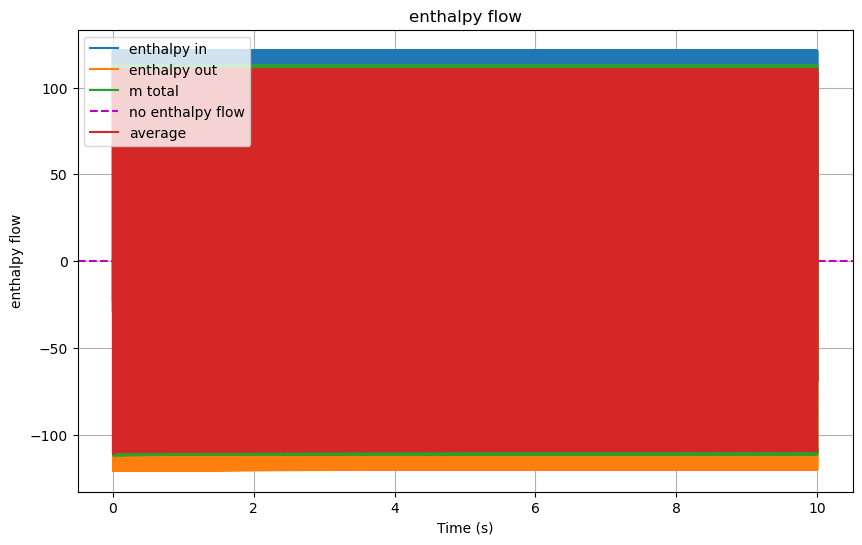

In [ ]:
#enthalpy flow
n_average = 50 # number of points we are averaging out

enthalpy_in = m_in * T_in * cp
enthalpy_out = m_out*T_cv*cp
plt.figure(figsize=(10, 6))

plt.plot(t,enthalpy_in, label='enthalpy in')
plt.plot(t,enthalpy_out, label = 'enthalpy out')
plt.plot(t,enthalpy_out + enthalpy_in, label='m total')
plt.axhline(0.0, color='m', linestyle='--', label='no enthalpy flow')

plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean((enthalpy_out + enthalpy_in).reshape(-1, n_average), axis=1),label='average')
plt.xlabel('Time (s)')
plt.ylabel('enthalpy flow')
plt.title('enthalpy flow')
plt.legend()
plt.grid(True)
#plt.savefig(f"plots/Enthalpy_P_0={P0:.1f}__v0={v0:.2f}__f={f}.pdf")
plt.show()

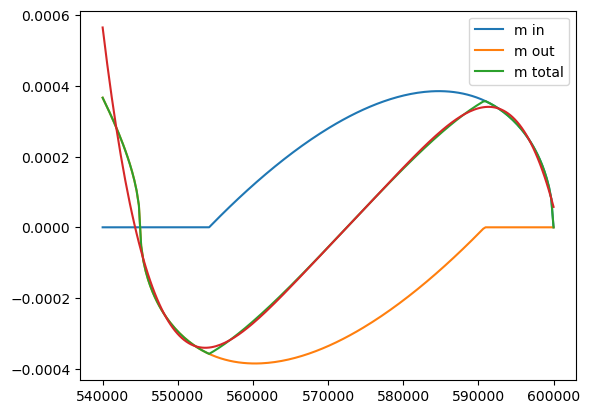

In [22]:
# '''Plot Reed Flow Curve'''
P_cv = np.linspace(5.4e5,6.0e5,200)
m_in = np.zeros_like(P_cv)
m_out = np.zeros_like(P_cv)
for i in range(len(P_cv)):
  dP_in = P_in - P_cv[i]
  dP_out = P_cv[i] - P_out
  m_in[i] = reed_flow(dP_in,m_max,dP_max)
  m_out[i] = -reed_flow(dP_out,m_max,dP_max)

m_total = m_in + m_out
plt.plot(P_cv,m_in,label='m in')
plt.plot(P_cv,m_out, label = 'm out')
plt.plot(P_cv,m_in + m_out, label='m total')
plt.plot(P_cv, (P_cv-5.725000e+05)*2.258589e-08 + (P_cv-5.725000e+05)**5 * (-3.582265e-26))
plt.legend()
plt.show()

Fitted parameters:
  P0 = 5.725398e+05
  a1 = 2.205697e-08
  a2 = -3.455770e-26


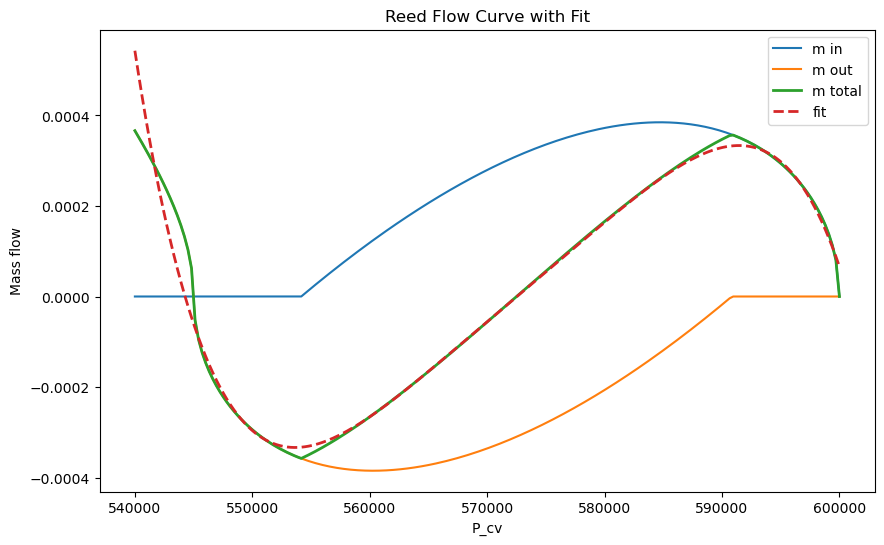

In [23]:
from scipy.optimize import curve_fit

def fit_func(P_cv, P0, a1, a2):
    return (P_cv - P0) * a1 + a2 * (P_cv - P0)**5

# Initial guesses for P0, a1, a2
# P0 should be near where m_total crosses zero (around 555000 from the plot)
p0_guess = [5.55e5, 1e-8, 1e-30]

# Perform the curve fit
popt, pcov = curve_fit(fit_func, P_cv, m_total, p0=p0_guess, maxfev=10000)

P0_fit, a1_fit, a2_fit = popt
print(f"Fitted parameters:")
print(f"  P0 = {P0_fit:.6e}")
print(f"  a1 = {a1_fit:.6e}")
print(f"  a2 = {a2_fit:.6e}")

# Generate fitted curve
m_fit = fit_func(P_cv, *popt)

# Plot results
plt.figure(figsize=(10, 6))
plt.plot(P_cv, m_in, label='m in')
plt.plot(P_cv, m_out, label='m out')
plt.plot(P_cv, m_total, label='m total', linewidth=2)
plt.plot(P_cv, m_fit, '--', label='fit', linewidth=2)
plt.legend()
plt.xlabel('P_cv')
plt.ylabel('Mass flow')
plt.title('Reed Flow Curve with Fit')
plt.show()

In [20]:
# =========================
# >>> Heat map: P0 vs v0 <<<
# =========================
# Drop this block after your existing code. It only *uses* the global parameters and
# the functions you already defined (reed_flow, acoustic_expander_ode).

# ================================
# >>> Parallel heatmap (joblib) <<<
# ================================
# Requirements in Colab (uncomment once):
# !pip -q install joblib

import os
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed


def _amplitude_half_pp(P_series, t_series, tail_window=0.1):
    """Half peak-to-peak amplitude over the last `tail_window` seconds."""
    if t_series.size < 5:
        return np.nan
    t_end = t_series[-1]
    mask = t_series >= (t_end - tail_window)
    if not np.any(mask):
        mask = slice(-max(10, t_series.size // 10), None)
    seg = P_series[mask]
    if seg.size < 3:
        return np.nan
    return 0.5 * (np.nanmax(seg) - np.nanmin(seg))

def simulate_once(P0_val, v0_val, t_span=(0.0, 1.0), n_eval=5000):
    """
    Run one simulation for given initial mean pressure P0_val (Pa)
    and initial velocity v0_val (m/s). Returns amplitude (Pa).
    Notes:
      - Uses your globals (P_in, P_out, R, cp, cv, A_neck, V0_cv, V0_pass, m_gas, b_gas, etc.).
      - P_pass uses P0_val via the global P0 inside acoustic_expander_ode, so we
        temporarily set the module-global P0 to P0_val for this call.
    """
    global P0  # so acoustic_expander_ode sees it in P_pass
    P0_backup = P0
    try:
        P0 = float(P0_val)

        # Initial state consistent with P0_val and T0
        M0_cv = P0 * V0_cv / (R * T0)
        E0_cv = cv * M0_cv * T0
        x0 = 0.0
        y0 = [x0, float(v0_val), M0_cv, E0_cv]

        t_eval_local = np.linspace(t_span[0], t_span[1], n_eval)
        sol = solve_ivp(
            acoustic_expander_ode, t_span, y0,
            t_eval=t_eval_local, method='RK45', rtol=1e-6, atol=1e-8
        )
        t = sol.t
        x = sol.y[0]
        M_cv = sol.y[2]
        E_cv = sol.y[3]

        V_cv = V0_cv + x * A_neck
        T_cv = E_cv / (cv * M_cv)
        P_cv = M_cv * R * T_cv / V_cv

        return _amplitude_half_pp(P_cv, t, tail_window=0.1)  # Pa
    except Exception:
        return np.nan
    finally:
        P0 = P0_backup


def _amp_task(idx_v, idx_p, P0_val, v0_val, t_span, n_eval):
    """
    Small wrapper so joblib can run a single (P0, v0) evaluation in a child process.
    Relies on simulate_once(P0_val, v0_val, t_span, n_eval) being defined in this module.
    Returns (row_index, col_index, amplitude_Pa).
    """
    amp = simulate_once(P0_val, v0_val, t_span=t_span, n_eval=n_eval)  # <-- uses your function
    return idx_v, idx_p, amp

def plot_heatmap_P0_v0_parallel(
    P0_vals=None, v0_vals=None, t_span=(0.0, 1.0), n_eval=8000,
    n_jobs=-1, verbose=5, save_path="heatmap_P0_v0_parallel.pdf"
):
    """
    Parallel version of the P0–v0 sweep using joblib (process-based).
    - n_jobs: number of worker processes (-1 = all cores).
    - verbose: joblib progress verbosity (0..10). Try 5 for periodic updates.
    """
    # Defaults (reuse your module globals P0, etc.)
    if P0_vals is None:
        P0_vals = np.linspace(0.97 * P0, 1.03 * P0, 25)
    if v0_vals is None:
        v0_vals = np.linspace(-15.0, 15.0, 31)

    # Pre-allocate output
    heat = np.full((len(v0_vals), len(P0_vals)), np.nan, dtype=float)

    # Build task list (row-major so we can fill by indices returned from workers)
    tasks = []
    for i_v, v0_val in enumerate(v0_vals):
        for i_p, P0_val in enumerate(P0_vals):
            tasks.append((i_v, i_p, P0_val, v0_val, t_span, n_eval))

    # Limit BLAS/OpenMP oversubscription for child processes (speeds up solve_ivp)
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
    os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

    # Run in parallel
    results = Parallel(n_jobs=n_jobs, verbose=verbose, prefer="processes")(
        delayed(_amp_task)(i_v, i_p, P0_val, v0_val, t_span, n_eval)
        for (i_v, i_p, P0_val, v0_val, t_span, n_eval) in tasks
    )

    # Assemble the heat matrix
    for i_v, i_p, amp in results:
        heat[i_v, i_p] = amp

    # Plot
    fig, ax = plt.subplots(figsize=(8, 5.6))
    im = ax.imshow(
        heat,
        origin="lower",
        aspect="auto",
        extent=[P0_vals[0] / 1e5, P0_vals[-1] / 1e5, v0_vals[0], v0_vals[-1]],
    )
    ax.set_xlabel("Initial pressure $P_0$ [bar]")
    ax.set_ylabel("Initial velocity $v_0$ [m/s]")
    ax.set_title("Oscillation amplitude of $P_{cv}$ after 1 s (half peak-to-peak)")
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Amplitude [Pa]")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    return heat, P0_vals, v0_vals



In [21]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, AutoMinorLocator, FuncFormatter
from joblib import Parallel, delayed


def generate_heatmap_data(
    P0_vals=None,
    v0_vals=None,
    t_span=(0.0, 1),
    n_eval=8000,
    n_jobs=-1,
    verbose=5,
):
    """
    Generate the P0–v0 sweep data using joblib (process-based).

    Returns
    -------
    heat : 2D array, shape (len(v0_vals), len(P0_vals))
        Heatmap values (amplitude).
    P0_vals : 1D array
    v0_vals : 1D array
    """
    # Defaults (reuse your module globals P0, etc.)
    if P0_vals is None:
        P0_vals = np.linspace(0.97 * P0, 1.03 * P0, 25)
    if v0_vals is None:
        v0_vals = np.linspace(-15.0, 15.0, 31)

    # Pre-allocate output
    heat = np.full((len(v0_vals), len(P0_vals)), np.nan, dtype=float)

    # Build task list
    tasks = []
    for i_v, v0_val in enumerate(v0_vals):
        for i_p, P0_val in enumerate(P0_vals):
            tasks.append((i_v, i_p, P0_val, v0_val, t_span, n_eval))

    # Limit BLAS/OpenMP oversubscription for child processes
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
    os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

    # Run in parallel
    results = Parallel(n_jobs=n_jobs, verbose=verbose, prefer="processes")(
        delayed(_amp_task)(i_v, i_p, P0_val, v0_val, t_span, n_eval)
        for (i_v, i_p, P0_val, v0_val, t_span, n_eval) in tasks
    )

    # Assemble the heat matrix
    for i_v, i_p, amp in results:
        heat[i_v, i_p] = amp

    return heat, P0_vals, v0_vals


def plot_heatmap_P0_v0(
    heat,
    P0_vals,
    v0_vals,
    save_path="heatmap_P0_v0_parallel.pdf",
    *,
    title=None,
    cmap="viridis",
    dpi_png=600,
    vertical_pressure_low = P_out,
    vertical_pressure_high = P_in,
):
    """
    Plot a publication-quality heatmap from pre-computed data.

    Parameters
    ----------
    heat : 2D array, shape (len(v0_vals), len(P0_vals))
        Heatmap values (amplitude).
    P0_vals : 1D array
        Pressure values in Pa.
    v0_vals : 1D array
        Velocity values in m/s.
    save_path : str or None
        Path to save the figure.
    title : str or None
        Custom title for the plot.
    cmap : str
        Colormap name.
    dpi_png : int
        DPI for PNG output.
    """
    # ----------------------------
    # Publication-style rcParams (local)
    # ----------------------------
    with mpl.rc_context({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,

        "axes.linewidth": 1.2,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "xtick.minor.width": 1.0,
        "ytick.minor.width": 1.0,
        "xtick.direction": "in",
        "ytick.direction": "in",

        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    }):
        # ----------------------------
        # Publication-quality heatmap
        # ----------------------------
        # Use bar for x-axis but keep amplitude label in Pa
        P0_bar = P0_vals / 1e5

        fig, ax = plt.subplots(figsize=(6.8, 4.8))  # 1-column-friendly

        # Robust color scaling (ignore NaNs)
        finite = np.isfinite(heat)
        if np.any(finite):
            vmin = np.nanpercentile(heat[finite], 1)
            vmax = np.nanpercentile(heat[finite], 99)
            if np.isclose(vmin, vmax):
                vmin, vmax = None, None
        else:
            vmin, vmax = None, None

        im = ax.imshow(
            heat,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            extent=[P0_bar.min(), P0_bar.max(), v0_vals.min(), v0_vals.max()],
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        vertical_pressure_low_bar = vertical_pressure_low / 1e5  # P_in / 1e5
        vertical_pressure_high_bar = vertical_pressure_high / 1e5  # P_out / 1e5

        # Vertical lines at inlet/outlet pressures
        line_in = ax.axvline(
            vertical_pressure_high_bar, linestyle="--", linewidth=2.4,
            color="tab:red", label=r"$P_{\mathrm{in}}$"
        )
        line_out = ax.axvline(
            vertical_pressure_low_bar, linestyle="--", linewidth=2.4,
            color="tab:blue", label=r"$P_{\mathrm{out}}$"
        )

        # If you're using text labels, color-match them too
        y_top = v0_vals.max()
        ax.text(vertical_pressure_high_bar, y_top, r"$P_{\mathrm{high}}$", rotation=90,
        va="bottom", ha="right", color=line_in.get_color())
        ax.text(vertical_pressure_low_bar, y_top, r"$P_{\mathrm{low}}$", rotation=90,
        va="bottom", ha="right", color=line_out.get_color())

        ax.set_xlabel(r"Initial pressure $P_0$ (bar)")
        ax.set_ylabel(r"Initial velocity $v_0$ (m/s)")
        ax.set_title(title or r"Oscillation amplitude of $P_{cv}$ (half peak-to-peak)")

        # Ticks: clean and not too dense
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.yaxis.set_major_locator(MaxNLocator(6))
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(which="both", top=False, right=False)

        # Clean spines (common in publications)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Colorbar styling
        cbar = fig.colorbar(im, ax=ax, pad=0.02)
        cbar.set_label(r"Amplitude (Pa)")
        cbar.outline.set_linewidth(1.2)
        cbar.ax.tick_params(width=1.2, direction="in")

        # If you want scientific notation on the colorbar ticks (optional)
        cbar.formatter = mpl.ticker.ScalarFormatter(useMathText=True)
        cbar.formatter.set_powerlimits((-2, 2))
        cbar.update_ticks()

        # ----------------------------
        # Save: vector + high-res raster
        # ----------------------------
        if save_path:
            root, ext = os.path.splitext(save_path)
            ext = ext.lower()

            # Always save a vector PDF (best for papers) unless user asked for something else explicitly
            if ext in [".pdf", ".svg"]:
                fig.savefig(save_path)  # vector
            else:
                # keep their extension, but also write a PDF alongside
                fig.savefig(save_path, dpi=dpi_png)
                fig.savefig(root + ".pdf")

            # also write a high-res PNG alongside (handy for slides)
            fig.savefig(root + ".png", dpi=dpi_png)

        plt.show()

        return fig, ax


def plot_heatmap_P0_v0_parallel1(
    P0_vals=None,
    v0_vals=None,
    t_span=(0.0, 1.0),
    n_eval=8000,
    n_jobs=-1,
    verbose=5,
    save_path="heatmap_P0_v0_parallel.pdf",
    *,
    title=None,
    cmap="viridis",
    dpi_png=600,
):
    """
    Convenience wrapper that generates data and plots in one call.
    (Preserves original API for backwards compatibility.)

    Returns
    -------
    heat : 2D array, shape (len(v0_vals), len(P0_vals))
        Heatmap values (amplitude).
    P0_vals : 1D array
    v0_vals : 1D array
    """
    # Generate data
    heat, P0_vals, v0_vals = generate_heatmap_data(
        P0_vals=P0_vals,
        v0_vals=v0_vals,
        t_span=t_span,
        n_eval=n_eval,
        n_jobs=n_jobs,
        verbose=verbose,
    )

    # Plot
    plot_heatmap_P0_v0(
        heat,
        P0_vals,
        v0_vals,
        save_path=save_path,
        title=title,
        cmap=cmap,
        dpi_png=dpi_png,
    )

    return heat, P0_vals, v0_vals

In [22]:
# Generate data once (slow part)

P0_range = np.linspace(P_out*0.99, P_in*1.01, 40)   # adjust as needed
v0_range = np.linspace(-20.0, 20.0, 40)

p0_min_bar = P0_range.min() / 1e5
p0_max_bar = P0_range.max() / 1e5
v0_min     = v0_range.min()
v0_max     = v0_range.max()
heat, P0_vals, v0_vals = generate_heatmap_data(
    P0_vals=P0_range,
    v0_vals=v0_range,
    n_jobs=-1,
    verbose=5,
)

# Plot as many times as you want with different settings (fast part)
# plot_heatmap_P0_v0(heat, P0_vals, v0_vals, save_path="plot1.pdf", cmap="viridis")


# # Or use the original combined function for backwards compatibility
# heat, P0_vals, v0_vals = pheat, P0_vals, v0_vals = plot_heatmap_P0_v0_parallel1(
#         P0_vals=P0_range,
#         v0_vals=v0_range,
#         t_span=(0.0, 1.5),
#         n_eval=10000,
#         n_jobs=-1,
#         verbose=5,
#         save_path=save_path,
    # )

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    4.8s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:   11.1s
[Parallel(n_jobs=-1)]: Done 264 tasks      | elapsed:   19.6s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   32.7s
[Parallel(n_jobs=-1)]: Done 624 tasks      | elapsed:   50.3s
[Parallel(n_jobs=-1)]: Done 858 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 1128 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 1434 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done 1600 out of 1600 | elapsed:  2.0min finished


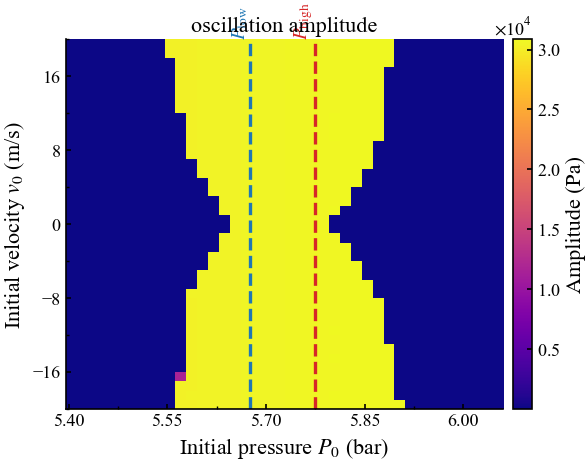

(<Figure size 680x480 with 2 Axes>,
 <Axes: title={'center': 'oscillation amplitude'}, xlabel='Initial pressure $P_0$ (bar)', ylabel='Initial velocity $v_0$ (m/s)'>)

In [59]:
plot_heatmap_P0_v0(heat, P0_vals, v0_vals, save_path="plotttttt.pdf", cmap="plasma", title="oscillation amplitude", vertical_pressure_high=577426, vertical_pressure_low=567645)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    4.9s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:   10.9s
[Parallel(n_jobs=-1)]: Done 264 tasks      | elapsed:   17.4s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   25.2s


NaN count : 0 / 625
Amplitude : 0.1 – 31535.0 Pa


[Parallel(n_jobs=-1)]: Done 625 out of 625 | elapsed:   33.5s finished


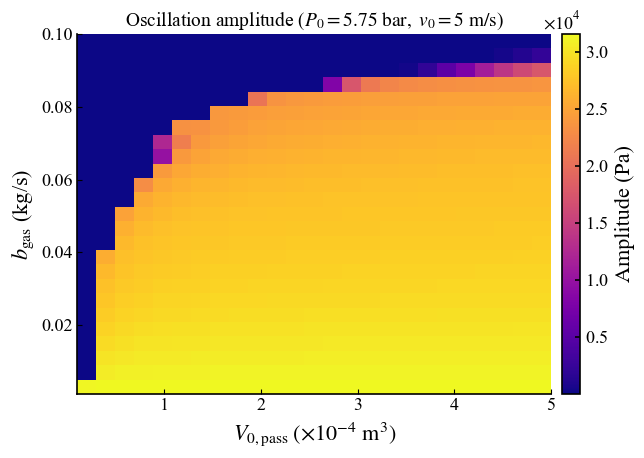

In [25]:

# ============================================================
# Heatmap: V0_pass vs b_gas
# Fixed: P_0 = 5.75 bar, v0 = 5 m/s
# Self-contained: ODE is a local closure — no global mutation
# needed so joblib workers get the right values every time.
# ============================================================
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from joblib import Parallel, delayed

# Snapshot all module-level constants needed by the ODE into
# plain local names. cloudpickle captures these automatically.
_P_in   = P_in;   _P_out  = P_out
_R      = R;      _cp     = cp;    _cv = cv;  _gamma = gamma
_T0     = T0;     _T_in   = T_in
_A_neck = A_neck; _V0_cv  = V0_cv; _m_gas = m_gas
_m_max  = m_max;  _dP_max = dP_max
_P0_fix = 5.75e5  # fixed initial pressure (Pa)
_v0_fix = 5.0     # fixed initial velocity (m/s)


def _reed_Vb(dP, m_, dp_):
    u = dP / dp_
    if 0 < dP < dp_:
        return m_ * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_ * (1 - u) * np.sqrt(-u)
    return 0.0


def _sim_Vb(V0p, bg, t_span=(0.0, 1.0), n_eval=8000):
    """
    Run one simulation with passive-cavity volume V0p (m^3) and
    gas damping bg (kg/s). Returns half peak-to-peak pressure
    amplitude (Pa) over the last 0.1 s.
    """

    # Local closure — V0p and bg are captured by value here,
    # so each worker gets its own correct copy.
    def ode(t, y):
        x, v, M_cv, E_cv = y
        V_cv = _V0_cv + x * _A_neck
        T_cv = E_cv / (_cv * M_cv) if M_cv > 1e-20 else _T0
        P_cv = M_cv * _R * T_cv / V_cv
        V_p  = V0p - x * _A_neck
        P_p  = _P0_fix * (V0p / V_p) ** _gamma if V_p > 1e-20 else _P0_fix
        m_in  = _reed_Vb(_P_in - P_cv, _m_max, _dP_max)
        m_out = _reed_Vb(P_cv - _P_out, _m_max, _dP_max)
        dVdt  = _A_neck * v
        return [
            v,
            (P_cv - P_p) * _A_neck / _m_gas - (bg / _m_gas) * v,
            m_in - m_out,
            -P_cv * dVdt + m_in * _cp * _T_in - m_out * _cp * T_cv,
        ]

    M0 = _P0_fix * _V0_cv / (_R * _T0)
    E0 = _cv * M0 * _T0
    y0 = [0.0, _v0_fix, M0, E0]

    try:
        sol  = solve_ivp(ode, t_span, y0,
                         t_eval=np.linspace(*t_span, n_eval),
                         method='RK45', rtol=1e-6, atol=1e-8)
        x_   = sol.y[0]; M_ = sol.y[2]; E_ = sol.y[3]
        V_   = _V0_cv + x_ * _A_neck
        T_   = E_ / (_cv * M_)
        P_   = M_ * _R * T_ / V_
        mask = sol.t >= sol.t[-1] - 0.1
        seg  = P_[mask]
        return 0.5 * (np.nanmax(seg) - np.nanmin(seg)) if seg.size >= 3 else np.nan
    except Exception:
        return np.nan


def _task_Vb(i_V, i_b, V0p, bg, t_span, n_eval):
    return i_V, i_b, _sim_Vb(V0p, bg, t_span, n_eval)


# ---- sweep grid ----
n_V = 25; n_b = 25
V0p_arr = np.linspace(1e-5, 5e-4, n_V)
bg_arr  = np.linspace(0.001, 0.1,  n_b)

for k, v in [("OMP_NUM_THREADS","1"), ("OPENBLAS_NUM_THREADS","1"),
             ("MKL_NUM_THREADS","1"),  ("VECLIB_MAXIMUM_THREADS","1")]:
    os.environ[k] = v

tasks_Vb = [(i_V, i_b, Vv, bv, (0.0, 1.0), 8000)
            for i_V, Vv in enumerate(V0p_arr)
            for i_b, bv in enumerate(bg_arr)]

results_Vb = Parallel(n_jobs=-1, verbose=5, prefer="processes")(
    delayed(_task_Vb)(i_V, i_b, Vv, bv, ts, ne)
    for i_V, i_b, Vv, bv, ts, ne in tasks_Vb
)

heat_Vb = np.full((n_b, n_V), np.nan)
for i_V, i_b, amp in results_Vb:
    heat_Vb[i_b, i_V] = amp

print(f"NaN count : {np.isnan(heat_Vb).sum()} / {heat_Vb.size}")
print(f"Amplitude : {np.nanmin(heat_Vb):.1f} – {np.nanmax(heat_Vb):.1f} Pa")

# ---- plot ----
with mpl.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14, "axes.labelsize": 16, "axes.titlesize": 14,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.linewidth": 1.2,
    "xtick.direction": "in", "ytick.direction": "in",
}):
    fig, ax = plt.subplots(figsize=(6.8, 4.8))
    finite = heat_Vb[np.isfinite(heat_Vb)]
    vmin = finite.min() if finite.size else None
    vmax = finite.max() if finite.size else None
    im = ax.imshow(
        heat_Vb, origin="lower", aspect="auto", interpolation="nearest",
        extent=[V0p_arr[0]*1e4, V0p_arr[-1]*1e4, bg_arr[0], bg_arr[-1]],
        cmap="plasma", vmin=vmin, vmax=vmax,
    )
    ax.set_xlabel(r"$V_{0,\mathrm{pass}}\;(\times10^{-4}\ \mathrm{m}^3)$")
    ax.set_ylabel(r"$b_\mathrm{gas}$ (kg/s)")
    ax.set_title(r"Oscillation amplitude ($P_0 = 5.75\ \mathrm{bar},\ v_0 = 5\ \mathrm{m/s}$)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Amplitude (Pa)")
    cbar.outline.set_linewidth(1.2)
    cbar.ax.tick_params(width=1.2, direction="in")
    fmt = mpl.ticker.ScalarFormatter(useMathText=True)
    fmt.set_powerlimits((-2, 2))
    cbar.formatter = fmt; cbar.update_ticks()
    plt.tight_layout()
    plt.show()


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    4.9s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:    7.4s
[Parallel(n_jobs=-1)]: Done 264 tasks      | elapsed:   10.5s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   13.7s


NaN count : 0 / 625
Amplitude : 0.0 – 31521.1 Pa


[Parallel(n_jobs=-1)]: Done 625 out of 625 | elapsed:   17.3s finished


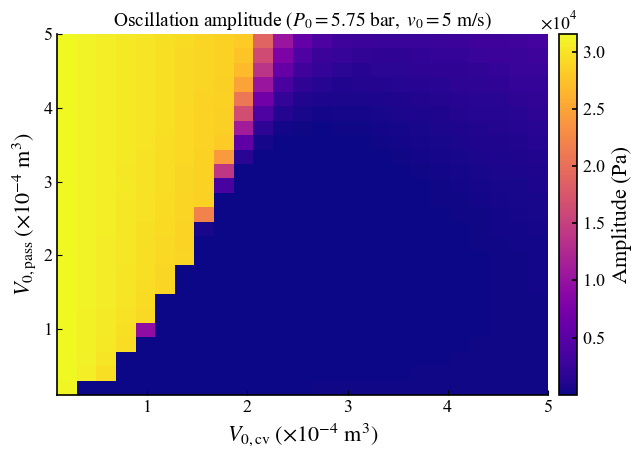

In [26]:

# ============================================================
# Heatmap: V0_cv vs V0_pass  (both 1e-5 to 5e-4)
# Fixed: P_0 = 5.75 bar, v0 = 5 m/s, b_gas unchanged
# ============================================================
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from joblib import Parallel, delayed

# Snapshot all constants needed by the ODE
_P_in2   = P_in;   _P_out2  = P_out
_R2      = R;      _cp2     = cp;    _cv2 = cv;  _gamma2 = gamma
_T02     = T0;     _T_in2   = T_in
_A_neck2 = A_neck; _m_gas2  = m_gas
_m_max2  = m_max;  _dP_max2 = dP_max
_b_gas2  = b_gas   # keep the current module-level b_gas fixed
_P0_fix2 = 5.75e5  # fixed initial pressure (Pa)
_v0_fix2 = 5.0     # fixed initial velocity (m/s)


def _reed2(dP, m_, dp_):
    u = dP / dp_
    if 0 < dP < dp_:
        return m_ * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_ * (1 - u) * np.sqrt(-u)
    return 0.0


def _sim_VcvVp(V0cv, V0p, t_span=(0.0, 1.0), n_eval=8000):
    """Simulate for given V0_cv and V0_pass; return tail half-pp amplitude (Pa)."""

    def ode(t, y):
        x, v, M_cv, E_cv = y
        V_cv = V0cv + x * _A_neck2
        T_cv = E_cv / (_cv2 * M_cv) if M_cv > 1e-20 else _T02
        P_cv = M_cv * _R2 * T_cv / V_cv
        V_p  = V0p - x * _A_neck2
        P_p  = _P0_fix2 * (V0p / V_p) ** _gamma2 if V_p > 1e-20 else _P0_fix2
        m_in  = _reed2(_P_in2 - P_cv, _m_max2, _dP_max2)
        m_out = _reed2(P_cv - _P_out2, _m_max2, _dP_max2)
        dVdt  = _A_neck2 * v
        return [
            v,
            (P_cv - P_p) * _A_neck2 / _m_gas2 - (_b_gas2 / _m_gas2) * v,
            m_in - m_out,
            -P_cv * dVdt + m_in * _cp2 * _T_in2 - m_out * _cp2 * T_cv,
        ]

    M0 = _P0_fix2 * V0cv / (_R2 * _T02)
    E0 = _cv2 * M0 * _T02
    y0 = [0.0, _v0_fix2, M0, E0]

    try:
        sol  = solve_ivp(ode, t_span, y0,
                         t_eval=np.linspace(*t_span, n_eval),
                         method='RK45', rtol=1e-6, atol=1e-8)
        x_   = sol.y[0]; M_ = sol.y[2]; E_ = sol.y[3]
        V_   = V0cv + x_ * _A_neck2
        T_   = E_ / (_cv2 * M_)
        P_   = M_ * _R2 * T_ / V_
        mask = sol.t >= sol.t[-1] - 0.1
        seg  = P_[mask]
        return 0.5 * (np.nanmax(seg) - np.nanmin(seg)) if seg.size >= 3 else np.nan
    except Exception:
        return np.nan


def _task_VcvVp(i_cv, i_p, Vcv, Vp, t_span, n_eval):
    return i_cv, i_p, _sim_VcvVp(Vcv, Vp, t_span, n_eval)


# ---- sweep grid ----
n_cv = 25; n_p = 25
Vcv_arr = np.linspace(1e-5, 5e-4, n_cv)   # V0_cv axis
Vp_arr  = np.linspace(1e-5, 5e-4, n_p)    # V0_pass axis

for k, val in [("OMP_NUM_THREADS","1"), ("OPENBLAS_NUM_THREADS","1"),
               ("MKL_NUM_THREADS","1"),  ("VECLIB_MAXIMUM_THREADS","1")]:
    os.environ[k] = val

tasks_VV = [(i_cv, i_p, Vcv, Vp, (0.0, 1.0), 8000)
            for i_cv, Vcv in enumerate(Vcv_arr)
            for i_p,  Vp  in enumerate(Vp_arr)]

results_VV = Parallel(n_jobs=-1, verbose=5, prefer="processes")(
    delayed(_task_VcvVp)(i_cv, i_p, Vcv, Vp, ts, ne)
    for i_cv, i_p, Vcv, Vp, ts, ne in tasks_VV
)

# heat[i_p, i_cv]  →  y-axis = V0_pass, x-axis = V0_cv
heat_VV = np.full((n_p, n_cv), np.nan)
for i_cv, i_p, amp in results_VV:
    heat_VV[i_p, i_cv] = amp

print(f"NaN count : {np.isnan(heat_VV).sum()} / {heat_VV.size}")
print(f"Amplitude : {np.nanmin(heat_VV):.1f} – {np.nanmax(heat_VV):.1f} Pa")

# ---- plot ----
with mpl.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14, "axes.labelsize": 16, "axes.titlesize": 14,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.linewidth": 1.2,
    "xtick.direction": "in", "ytick.direction": "in",
}):
    fig, ax = plt.subplots(figsize=(6.8, 4.8))
    finite = heat_VV[np.isfinite(heat_VV)]
    vmin = finite.min() if finite.size else None
    vmax = finite.max() if finite.size else None
    im = ax.imshow(
        heat_VV, origin="lower", aspect="auto", interpolation="nearest",
        extent=[Vcv_arr[0]*1e4, Vcv_arr[-1]*1e4,
                Vp_arr[0]*1e4,  Vp_arr[-1]*1e4],
        cmap="plasma", vmin=vmin, vmax=vmax,
    )
    ax.set_xlabel(r"$V_{0,\mathrm{cv}}\;(\times10^{-4}\ \mathrm{m}^3)$")
    ax.set_ylabel(r"$V_{0,\mathrm{pass}}\;(\times10^{-4}\ \mathrm{m}^3)$")
    ax.set_title(r"Oscillation amplitude ($P_0 = 5.75\ \mathrm{bar},\ v_0 = 5\ \mathrm{m/s}$)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Amplitude (Pa)")
    cbar.outline.set_linewidth(1.2)
    cbar.ax.tick_params(width=1.2, direction="in")
    fmt = mpl.ticker.ScalarFormatter(useMathText=True)
    fmt.set_powerlimits((-2, 2))
    cbar.formatter = fmt; cbar.update_ticks()
    plt.tight_layout()
    plt.show()


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    4.9s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:   12.8s
[Parallel(n_jobs=-1)]: Done 264 tasks      | elapsed:   21.5s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   31.4s


NaN count : 0 / 625
Amplitude : 0.1 – 31156.9 Pa


[Parallel(n_jobs=-1)]: Done 625 out of 625 | elapsed:   41.3s finished


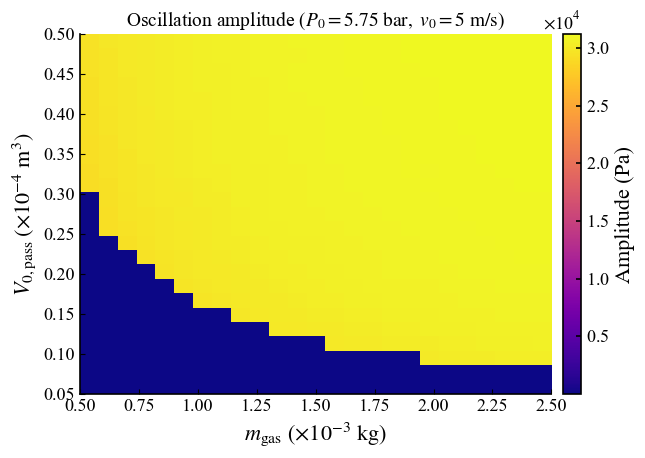

In [30]:

# ============================================================
# Heatmap: m_gas (0.0005–0.01) vs V0_pass (1e-5–5e-4)
# Fixed: P_0 = 5.75 bar, v0 = 5 m/s, b_gas unchanged
# ============================================================
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from joblib import Parallel, delayed

_P_in3   = P_in;   _P_out3  = P_out
_R3      = R;      _cp3     = cp;    _cv3 = cv;  _gamma3 = gamma
_T03     = T0;     _T_in3   = T_in
_A_neck3 = A_neck; _V0_cv3  = V0_cv
_m_max3  = m_max;  _dP_max3 = dP_max
_b_gas3  = b_gas
_P0_fix3 = 5.75e5
_v0_fix3 = 5.0


def _reed3(dP, m_, dp_):
    u = dP / dp_
    if 0 < dP < dp_:
        return m_ * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_ * (1 - u) * np.sqrt(-u)
    return 0.0


def _sim_mgVp(mg, V0p, t_span=(0.0, 1.0), n_eval=8000):
    """Simulate for given m_gas=mg and V0_pass=V0p; return tail half-pp amplitude (Pa)."""

    def ode(t, y):
        x, v, M_cv, E_cv = y
        V_cv = _V0_cv3 + x * _A_neck3
        T_cv = E_cv / (_cv3 * M_cv) if M_cv > 1e-20 else _T03
        P_cv = M_cv * _R3 * T_cv / V_cv
        V_p  = V0p - x * _A_neck3
        P_p  = _P0_fix3 * (V0p / V_p) ** _gamma3 if V_p > 1e-20 else _P0_fix3
        m_in  = _reed3(_P_in3 - P_cv, _m_max3, _dP_max3)
        m_out = _reed3(P_cv - _P_out3, _m_max3, _dP_max3)
        dVdt  = _A_neck3 * v
        return [
            v,
            (P_cv - P_p) * _A_neck3 / mg - (_b_gas3 / mg) * v,
            m_in - m_out,
            -P_cv * dVdt + m_in * _cp3 * _T_in3 - m_out * _cp3 * T_cv,
        ]

    M0 = _P0_fix3 * _V0_cv3 / (_R3 * _T03)
    E0 = _cv3 * M0 * _T03
    y0 = [0.0, _v0_fix3, M0, E0]

    try:
        sol  = solve_ivp(ode, t_span, y0,
                         t_eval=np.linspace(*t_span, n_eval),
                         method='RK45', rtol=1e-6, atol=1e-8)
        x_   = sol.y[0]; M_ = sol.y[2]; E_ = sol.y[3]
        V_   = _V0_cv3 + x_ * _A_neck3
        T_   = E_ / (_cv3 * M_)
        P_   = M_ * _R3 * T_ / V_
        mask = sol.t >= sol.t[-1] - 0.1
        seg  = P_[mask]
        return 0.5 * (np.nanmax(seg) - np.nanmin(seg)) if seg.size >= 3 else np.nan
    except Exception:
        return np.nan


def _task_mgVp(i_m, i_p, mg, Vp, t_span, n_eval):
    return i_m, i_p, _sim_mgVp(mg, Vp, t_span, n_eval)


# ---- sweep grid ----
n_m = 25; n_p = 25
mg_arr  = np.linspace(0.0005, 0.0025,  n_m)   # m_gas axis
Vp3_arr = np.linspace(5e-6,   5e-5,  n_p)   # V0_pass axis

for k, val in [("OMP_NUM_THREADS","1"), ("OPENBLAS_NUM_THREADS","1"),
               ("MKL_NUM_THREADS","1"),  ("VECLIB_MAXIMUM_THREADS","1")]:
    os.environ[k] = val

tasks_mV = [(i_m, i_p, mg, Vp, (0.0, 1.0), 8000)
            for i_m, mg in enumerate(mg_arr)
            for i_p, Vp in enumerate(Vp3_arr)]

results_mV = Parallel(n_jobs=-1, verbose=5, prefer="processes")(
    delayed(_task_mgVp)(i_m, i_p, mg, Vp, ts, ne)
    for i_m, i_p, mg, Vp, ts, ne in tasks_mV
)

# heat[i_p, i_m]  →  y-axis = V0_pass, x-axis = m_gas
heat_mV = np.full((n_p, n_m), np.nan)
for i_m, i_p, amp in results_mV:
    heat_mV[i_p, i_m] = amp

print(f"NaN count : {np.isnan(heat_mV).sum()} / {heat_mV.size}")
print(f"Amplitude : {np.nanmin(heat_mV):.1f} – {np.nanmax(heat_mV):.1f} Pa")

# ---- plot ----
with mpl.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14, "axes.labelsize": 16, "axes.titlesize": 14,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.linewidth": 1.2,
    "xtick.direction": "in", "ytick.direction": "in",
}):
    fig, ax = plt.subplots(figsize=(6.8, 4.8))
    finite = heat_mV[np.isfinite(heat_mV)]
    vmin = finite.min() if finite.size else None
    vmax = finite.max() if finite.size else None
    im = ax.imshow(
        heat_mV, origin="lower", aspect="auto", interpolation="nearest",
        extent=[mg_arr[0]*1e3, mg_arr[-1]*1e3,
                Vp3_arr[0]*1e4, Vp3_arr[-1]*1e4],
        cmap="plasma", vmin=vmin, vmax=vmax,
    )
    ax.set_xlabel(r"$m_\mathrm{gas}$ ($\times10^{-3}\ \mathrm{kg}$)")
    ax.set_ylabel(r"$V_{0,\mathrm{pass}}\;(\times10^{-4}\ \mathrm{m}^3)$")
    ax.set_title(r"Oscillation amplitude ($P_0 = 5.75\ \mathrm{bar},\ v_0 = 5\ \mathrm{m/s}$)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Amplitude (Pa)")
    cbar.outline.set_linewidth(1.2)
    cbar.ax.tick_params(width=1.2, direction="in")
    fmt = mpl.ticker.ScalarFormatter(useMathText=True)
    fmt.set_powerlimits((-2, 2))
    cbar.formatter = fmt; cbar.update_ticks()
    plt.tight_layout()
    plt.show()
